# Band-Pass Filter
In this part we will develop a band pass filter by using two low pass filters and the spectral inversion method covered before. A Band-Pass filter is just a combination of different filters. To generate a band pass filter we can perform the following steps:
1. Design two low-pass filters with frequecies $f_a$ and $f_b$. Where $f_a < f_b$.
2. Spectrally invert the low-pass filter with frequency $f_b$.
3. Add both filter kernels.
4. Spectrally invert the filter generated in the previous step.

<font color="blue">Note: In order to run this Jupyter Notebook you must create a file named `aux_functions.py` inside the folder containing this Notebook with the following functions `get_fourier`, `shifted_sinc_function`,  `hamming_window`, `blackman_window`, `spectral_reversal` and `spectral_inversion` which were developed previously.</font> 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pickle

from aux_functions import get_fourier, shifted_sinc_function, blackman_window, hamming_window, spectral_inversion, spectral_reversal
from aux_plots import plot_frequency_response

# Designing a Band Pass Filter
In this part we will create a band pass filter with a normalized band pass frequency between 0.14 and 0.25. To do so, the four steps described before will be applied. Later you will see that if we ommit step four, spectrally invert the filter generated by previous steps, you can generate a band reject filter too.

## Step 1: Design two low-pass filters
First, you need to design two low pass filters with frequencies `fc_1` and `fc_2`, where `fc_1` $<$ `fc_2`. These filters will be implemented using the window method, for this purpose you will use the `shifted_sinc_function` and `blackman_window` functions.

In [2]:
# Set a normalized cut-off frequency of 0.14 and assign it to fc_1
### BEGIN SOLUTION
fc_1 = 0.14
### END SOLUTION

# Set a normalized cut-off frequency of 0.25 and assign it to fc_2
### BEGIN SOLUTION
fc_2 = 0.25
### END SOLUTION

# Se a transition bandwidth BW to 0.04
### BEGIN SOLUTION
BW = 0.04
### END SOLUTION

# Calculate the number of coefficients of the filter and assign it to a variable named M
### BEGIN SOLUTION
M = int(4/BW)
### END SOLUTION

print("Filter lenght is {}".format(M))

Filter lenght is 100


In [3]:
# Implement a sinc filter with a Blackman window.
# Use a cut-off frequency fc_1 and a transition bandwidth BW calculated before.
# Assign your result to a variable named filter_lp_fc_1
### BEGIN SOLUTION
filter_lp_fc_1 = shifted_sinc_function(fc_1, BW)*blackman_window(BW)
### END SOLUTION

# Normalize your filter_lp_fc_1 coefficients and assign it to 
# a variable named normalized_shifted_sinc_1
### BEGIN SOLUTION
normalized_shifted_sinc_1 = filter_lp_fc_1/filter_lp_fc_1.sum()
### END SOLUTION

# Implement a sinc filter with a Blackman window.
# Use a cut-off frequency fc_2 and a transition bandwidth BW calculated before.
# Assign your result to a variable named filter_lp_fc_2
### BEGIN SOLUTION
filter_lp_fc_2 = shifted_sinc_function(fc_2, BW)*blackman_window(BW)
### END SOLUTION

# Normalize your filter_lp_fc_2 coefficients and assign it to 
# a variable named normalized_shifted_sinc_2
### BEGIN SOLUTION
normalized_shifted_sinc_2 = filter_lp_fc_2/filter_lp_fc_2.sum()
### END SOLUTION

In [4]:
with open('band_pass_step_1.pkl', 'rb') as file:
    filter_lp_fc_1_pkl, normalized_shifted_sinc_1_pkl, \
    filter_lp_fc_2_pkl, normalized_shifted_sinc_2_pkl = pickle.load(file)

    
assert np.allclose(filter_lp_fc_1, filter_lp_fc_1_pkl, atol=0.01)
assert np.allclose(normalized_shifted_sinc_1, normalized_shifted_sinc_1_pkl, atol=0.01)
assert np.allclose(filter_lp_fc_2, filter_lp_fc_2_pkl, atol=0.01)
assert np.allclose(normalized_shifted_sinc_2, normalized_shifted_sinc_2_pkl, atol=0.01)

In [5]:
# Get the Fourier Transform of normalized_shifted_sinc_1 and assign the rusults as follows:
# * Magnitude to normalized_fft_shifted_sinc_1 
# * Normalized frequency to normalized_fft_shifted_sinc_1_freq
# Use the get_fourier function from aux_functions 
### BEGIN SOLUTION
normalized_fft_shifted_sinc_1, normalized_fft_shifted_sinc_1_freq = get_fourier(normalized_shifted_sinc_1)
### END SOLUTION

# Get the Fourier Transform of normalized_shifted_sinc_2 and assign the rusults as follows:
# * Magnitude to normalized_fft_shifted_sinc_2 
# * Normalized frequency to normalized_fft_shifted_sinc_2_freq
# Use the get_fourier function from aux_functions 
### BEGIN SOLUTION
normalized_fft_shifted_sinc_2, normalized_fft_shifted_sinc_2_freq = get_fourier(normalized_shifted_sinc_2)
### END SOLUTION

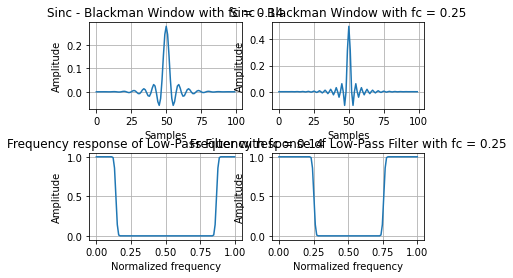

In [6]:
assert np.allclose(np.absolute(np.fft.fft(normalized_shifted_sinc_1)), normalized_fft_shifted_sinc_1)
assert np.allclose(np.absolute(np.fft.fft(normalized_shifted_sinc_2)), normalized_fft_shifted_sinc_2)
assert np.allclose(np.linspace(0,1, normalized_shifted_sinc_1.shape[0]), normalized_fft_shifted_sinc_1_freq)
assert np.allclose(np.linspace(0,1, normalized_shifted_sinc_2.shape[0]), normalized_fft_shifted_sinc_2_freq)


plt.rcParams["figure.figsize"] = (15,10)

plt.subplot(2,2,1)
plt.plot(normalized_shifted_sinc_1)
#plt.stem(normalized_shifted_sinc_1, markerfmt='.', use_line_collection=True)
plt.title('Sinc - Blackman Window with fc = {}'.format(fc_1))
plt.grid('on')
plt.xlabel('Samples')
plt.ylabel('Amplitude')

plt.subplot(2,2,2)
plt.plot(normalized_shifted_sinc_2)
#plt.stem(normalized_shifted_sinc_2, markerfmt='.', use_line_collection=True)
plt.title('Sinc - Blackman Window with fc = {}'.format(fc_2))
plt.grid('on')
plt.xlabel('Samples')
plt.ylabel('Amplitude')


plt.subplot(2,2,3)
plt.plot(normalized_fft_shifted_sinc_1_freq, normalized_fft_shifted_sinc_1)
plt.title('Frequency response of Low-Pass Filter with fc = {}'.format(fc_1))
plt.grid('on')
plt.xlabel('Normalized frequency')
plt.ylabel('Amplitude')

plt.subplot(2,2,4)
plt.plot(normalized_fft_shifted_sinc_2_freq, normalized_fft_shifted_sinc_2)
plt.title('Frequency response of Low-Pass Filter with fc = {}'.format(fc_2))
plt.grid('on')
plt.xlabel('Normalized frequency')
plt.ylabel('Amplitude')


plt.subplots_adjust(hspace=0.5)

## Step 2: Spectrally Invert the low pass filter with `fc_2`
Now that we have our two low pass filters, we need to use the filter with cut-off frequency `fc_2` to transform it to a high pass filter. For this, the spectral inversion method is used, although the spectral reversal method can also be applied.

In [7]:
# Define two variables:
# 1. low_pass which stores a copy of the normalized_shifted_sinc_1 coefficients
# 2. high_pass wich stores the spectral inversion coefficients obtained from normalized_shifted_sinc_2
### BEGIN SOLUTION
low_pass = np.copy(normalized_shifted_sinc_1)
high_pass = spectral_inversion(normalized_shifted_sinc_2)
### END SOLUTION

In [8]:
with open('band_pass_step_2.pkl', 'rb') as file:
    high_pass_pkl = pickle.load(file)

    
assert np.allclose(low_pass, normalized_shifted_sinc_1)
assert(hex(id(low_pass)) != hex(id(normalized_shifted_sinc_1))),  "Check your pointers!"
assert np.allclose(high_pass, high_pass_pkl, atol=0.01)

In [9]:
# Define three variables:
# 1. fft_low_pass which stores a copy of the normalized_fft_shifted_sinc_1 Fourier coefficients
# 2. fft_high_pass which stores the magnitude of the Fourier coefficients from get_fourier applied to high_pass
# 3. fft_high_pass_freq which stores the normalized frequency obtained from get_fourier applied to high_pass
### BEGIN SOLUTION
fft_low_pass = np.copy(normalized_fft_shifted_sinc_1)
fft_high_pass, fft_high_pass_freq = get_fourier(high_pass)
### END SOLUTION

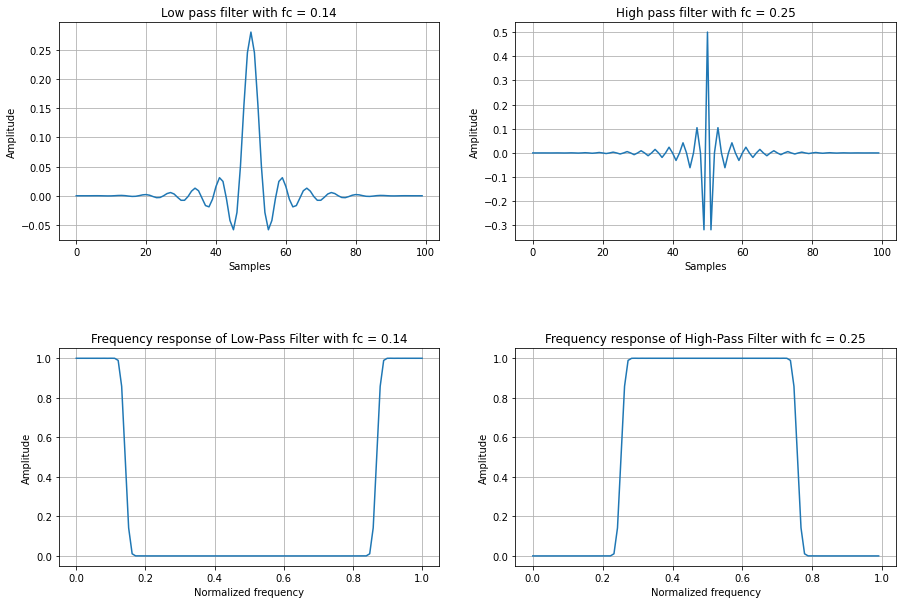

In [10]:
assert np.allclose(fft_low_pass, normalized_fft_shifted_sinc_1)
assert(hex(id(fft_low_pass)) != hex(id(normalized_fft_shifted_sinc_1))),  "Check your pointers!"

assert np.allclose(np.absolute(np.fft.fft(high_pass)), fft_high_pass)
assert np.allclose(np.linspace(0,1, high_pass.shape[0]), fft_high_pass_freq)

plt.rcParams["figure.figsize"] = (15,10)

plt.subplot(2,2,1)
#plt.stem(low_pass, markerfmt='.', use_line_collection=True)
plt.plot(low_pass)
plt.title('Low pass filter with fc = {}'.format(fc_1))
plt.grid('on')
plt.xlabel('Samples')
plt.ylabel('Amplitude')

plt.subplot(2,2,2)
#plt.stem(high_pass, markerfmt='.', use_line_collection=True)
plt.plot(high_pass)
plt.title('High pass filter with fc = {}'.format(fc_2))
plt.grid('on')
plt.xlabel('Samples')
plt.ylabel('Amplitude')


plt.subplot(2,2,3)
plt.plot(normalized_fft_shifted_sinc_1_freq, fft_low_pass)
plt.title('Frequency response of Low-Pass Filter with fc = {}'.format(fc_1))
plt.grid('on')
plt.xlabel('Normalized frequency')
plt.ylabel('Amplitude')

plt.subplot(2,2,4)
plt.plot(fft_high_pass_freq[:-1], fft_high_pass[:-1])
plt.title('Frequency response of High-Pass Filter with fc = {}'.format(fc_2))
plt.grid('on')
plt.xlabel('Normalized frequency')
plt.ylabel('Amplitude')


plt.subplots_adjust(hspace=0.5)

## Step 3: Add both filter kernels
The next step for you to create a band pass filter is to add both filter kernels. In this case, our filter kernels are the `low_pass` and `high_pass` filter coefficients. 

In [11]:
# Create an array named reject_band and add the low_pass and high_pass filter coefficients
### BEGIN SOLUTION
reject_band = low_pass + high_pass
### END SOLUTION

# Apply the Fourier Transform to reject_band
# Store the magnitude of the Fourier Transform in a variable named fft_reject_band
# Store the normalized frequency in a variable named fft_reject_band_freq
# Use the get_fourier function for this purpose.
### BEGIN SOLUTION
fft_reject_band, fft_reject_band_freq = get_fourier(reject_band)
### END SOLUTION

In [12]:
with open('band_pass_step_3.pkl', 'rb') as file:
    reject_band_pkl, fft_reject_band_pkl, fft_reject_band_freq_pkl = pickle.load(file)

assert np.allclose(reject_band, reject_band_pkl, atol=0.01)
assert np.allclose(fft_reject_band, fft_reject_band_pkl, atol=0.01)
assert np.allclose(fft_reject_band_freq, fft_reject_band_freq_pkl, atol=0.01)

## Step 4: Spectral Invert the previously generated filter
As the final step, to generate a band pass filter, we need to spectrally invert the `reject_band` filter coefficients. This will make and upside down version of the `reject_band` filter, which in turn will create the desired filter.

In [13]:
# Use the spectral_inversion function on the band reject filter to obtain a band pass filter.
# The coefficients of the band reject filter are stored in the reject_band variable.
# Store the result in a variable named band_pass.
### BEGIN SOLUTION
band_pass = spectral_inversion(reject_band)
### END SOLUTION

# Apply the Fourier Transform to band_pass
# Store the magnitude of the Fourier Transform in a variable named fft_band_pass
# Store the normalized frequency in a variable named fft_band_pass_freq
# Use the get_fourier function for this purpose.
### BEGIN SOLUTION
fft_band_pass, fft_band_pass_freq = get_fourier(band_pass)
### END SOLUTION

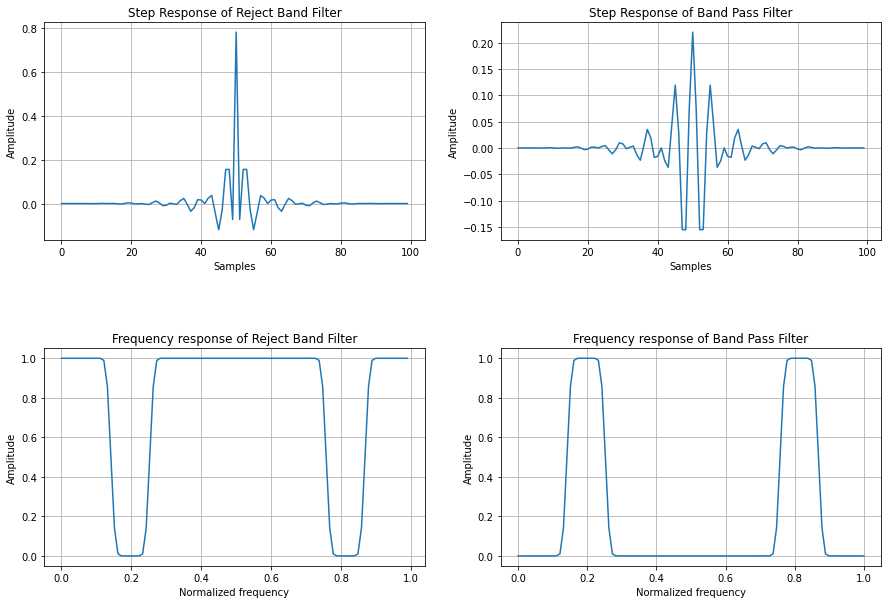

In [14]:
with open('band_pass_step_4.pkl', 'rb') as file:
    band_pass_pkl, fft_band_pass_pkl, fft_band_pass_freq_pkl = pickle.load(file)

assert np.allclose(band_pass, band_pass_pkl, atol=0.01)
assert np.allclose(fft_band_pass, fft_band_pass_pkl, atol=0.01)
assert np.allclose(fft_band_pass_freq, fft_band_pass_freq_pkl, atol=0.01) 

plt.rcParams["figure.figsize"] = (15,10)

plt.subplot(2,2,1)
#plt.stem(reject_band, markerfmt='.', use_line_collection=True)
plt.plot(reject_band)
plt.title('Step Response of Reject Band Filter')
plt.grid('on')
plt.xlabel('Samples')
plt.ylabel('Amplitude')

plt.subplot(2,2,2)
#plt.stem(band_pass, markerfmt='.', use_line_collection=True)
plt.plot(band_pass)
plt.title('Step Response of Band Pass Filter')
plt.grid('on')
plt.xlabel('Samples')
plt.ylabel('Amplitude')


plt.subplot(2,2,3)
plt.plot(fft_reject_band_freq[:-1], fft_reject_band[:-1])
plt.title('Frequency response of Reject Band Filter')
plt.grid('on')
plt.xlabel('Normalized frequency')
plt.ylabel('Amplitude')

plt.subplot(2,2,4)
plt.plot(fft_band_pass_freq, fft_band_pass)
plt.title('Frequency response of Band Pass Filter')
plt.grid('on')
plt.xlabel('Normalized frequency')
plt.ylabel('Amplitude')


plt.subplots_adjust(hspace=0.5)

#### Reference
* http://www.dspguide.com/ch16.htm
* https://tomroelandts.com/articles/how-to-create-simple-band-pass-and-band-reject-filters
* https://numpy.org/doc/stable/reference/generated/numpy.convolve.html
* https://tomroelandts.com/articles/spectral-reversal-to-create-a-high-pass-filter
* https://tomroelandts.com/articles/how-to-create-a-simple-high-pass-filter